# Telco Customer Churn - Data Cleaning and EDA
# Goal: Understand why customers churn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

## 1. First Look

In [2]:
df.shape

(7043, 21)

In [3]:

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 2. Data Cleaning - Check Missing & Fix Types

In [5]:
df[df['TotalCharges'] == ' '].shape

(11, 21)

In [6]:
df[df['TotalCharges'] == ' '][['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [7]:
# Now fix with proof
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Validation
print(df['TotalCharges'].dtype) # must be float64
print(df['TotalCharges'].isnull().sum()) # must be 0

float64
0


## 2.5 Data Cleaning - Final Validation

In [8]:
print("--- 1. Duplicates ---")
print(f"Duplicates: {df.duplicated().sum()}")

print("\n--- 2. Nulls ---")
print(df.isnull().sum())

print("\n--- 3. Data Types ---")
print(df.dtypes)

print("\n--- 4. Spaces in TotalCharges ---")
print(f"Spaces left: {(df['TotalCharges'] == ' ').sum()}")



--- 1. Duplicates ---
Duplicates: 0

--- 2. Nulls ---
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

--- 3. Data Types ---
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


C:\Users\asd\AppData\Local\Temp\ipykernel_6684\2452961707.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


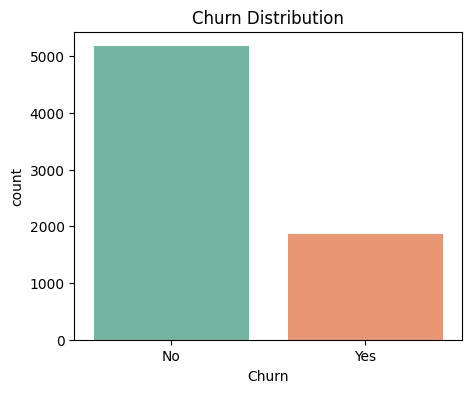

In [9]:
churn_counts = df['Churn'].value_counts(normalize=True) * 100
print(churn_counts)

# رسمة
plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Churn Distribution')
plt.show()

**Insight:** نسبة الـ Churn 26.5%، يعني من كل 4 عملاء واحد بيمشي. الداتا تعتبر Imbalanced بس مش بشكل كبير اوي، وهنحتاج نراعي ده في الموديل بعدين بالـ F1-Score.

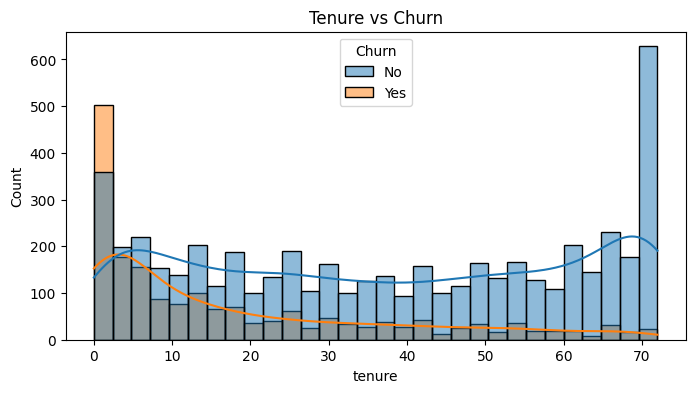

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [10]:
# هل الـ tenure ليه علاقة بالـ Churn؟
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True)
plt.title('Tenure vs Churn')
plt.show()

# متوسط الـ tenure
print(df.groupby('Churn')['tenure'].mean())

**Insight:** العميل اللي بيعمل Churn متوسط بقائه 18 شهر فقط، بينما العميل اللي بيستمر متوسط بقائه 37 شهر. ده معناه ان اول سنتين هما الاخطر، والشركة لازم تعمل عروض قوية للعملاء الجداد.

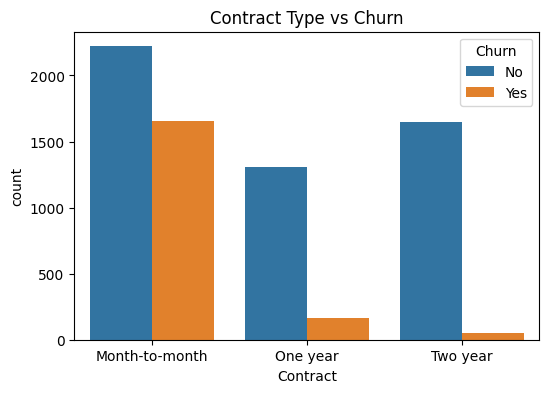

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [11]:
# علاقة العقد بالـ Churn
plt.figure(figsize=(6,4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Contract Type vs Churn')
plt.show()

# نسبة مئوية ادق
print(pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100)

**Insight (اهم واحد):** 42.7% من عملاء العقود الشهرية بيقطعوا الخدمة، مقابل 2.8% فقط لعملاء السنتين. ده معناه ان الشركة بتخسر بسبب نظام Month-to-Month. الحل: تحفيز العملاء للتحويل لعقود سنوية بخصم او مميزات.

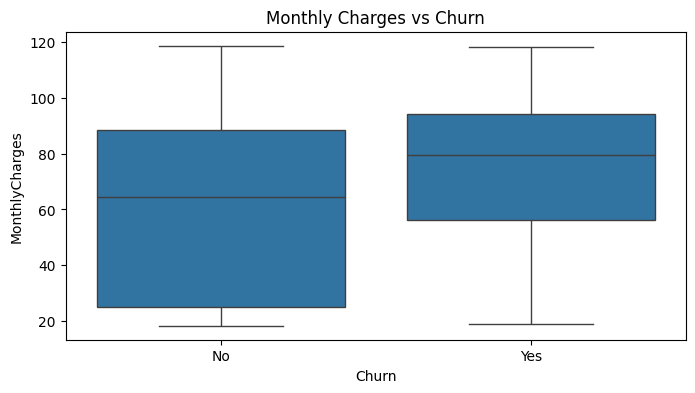

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [12]:
# هل الفاتورة الغالية بتطرد العميل؟
plt.figure(figsize=(8,4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.show()

print(df.groupby('Churn')['MonthlyCharges'].mean())

**Insight:** متوسط فاتورة العميل اللي مشي 74$ مقابل 61$ للعميل اللي استمر. العميل اللي بيدفع اكتر حاسس انه مش واخد قيمة مقابل السعر.

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


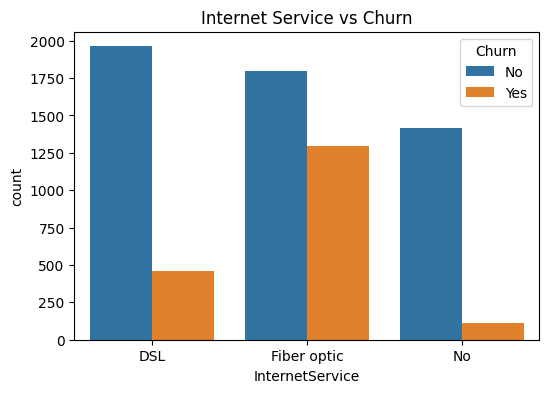

In [13]:
# Internet Service
print(pd.crosstab(df['InternetService'], df['Churn'], normalize='index')*100)

plt.figure(figsize=(6,4))
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Internet Service vs Churn')
plt.show()

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


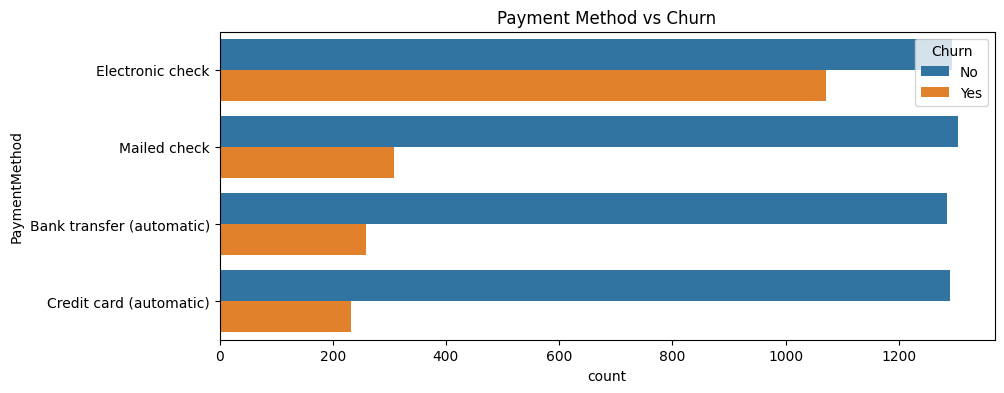

In [14]:
# Payment Method
print(pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index')*100)

plt.figure(figsize=(10,4))
sns.countplot(y='PaymentMethod', hue='Churn', data=df)
plt.title('Payment Method vs Churn')
plt.show()


--- OnlineSecurity ---
Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194

--- OnlineBackup ---
Churn                       No        Yes
OnlineBackup                             
No                   60.071244  39.928756
No internet service  92.595020   7.404980
Yes                  78.468506  21.531494

--- DeviceProtection ---
Churn                       No        Yes
DeviceProtection                         
No                   60.872375  39.127625
No internet service  92.595020   7.404980
Yes                  77.497936  22.502064

--- TechSupport ---
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341

--- StreamingTV ---
Churn                       No        Yes
Stre

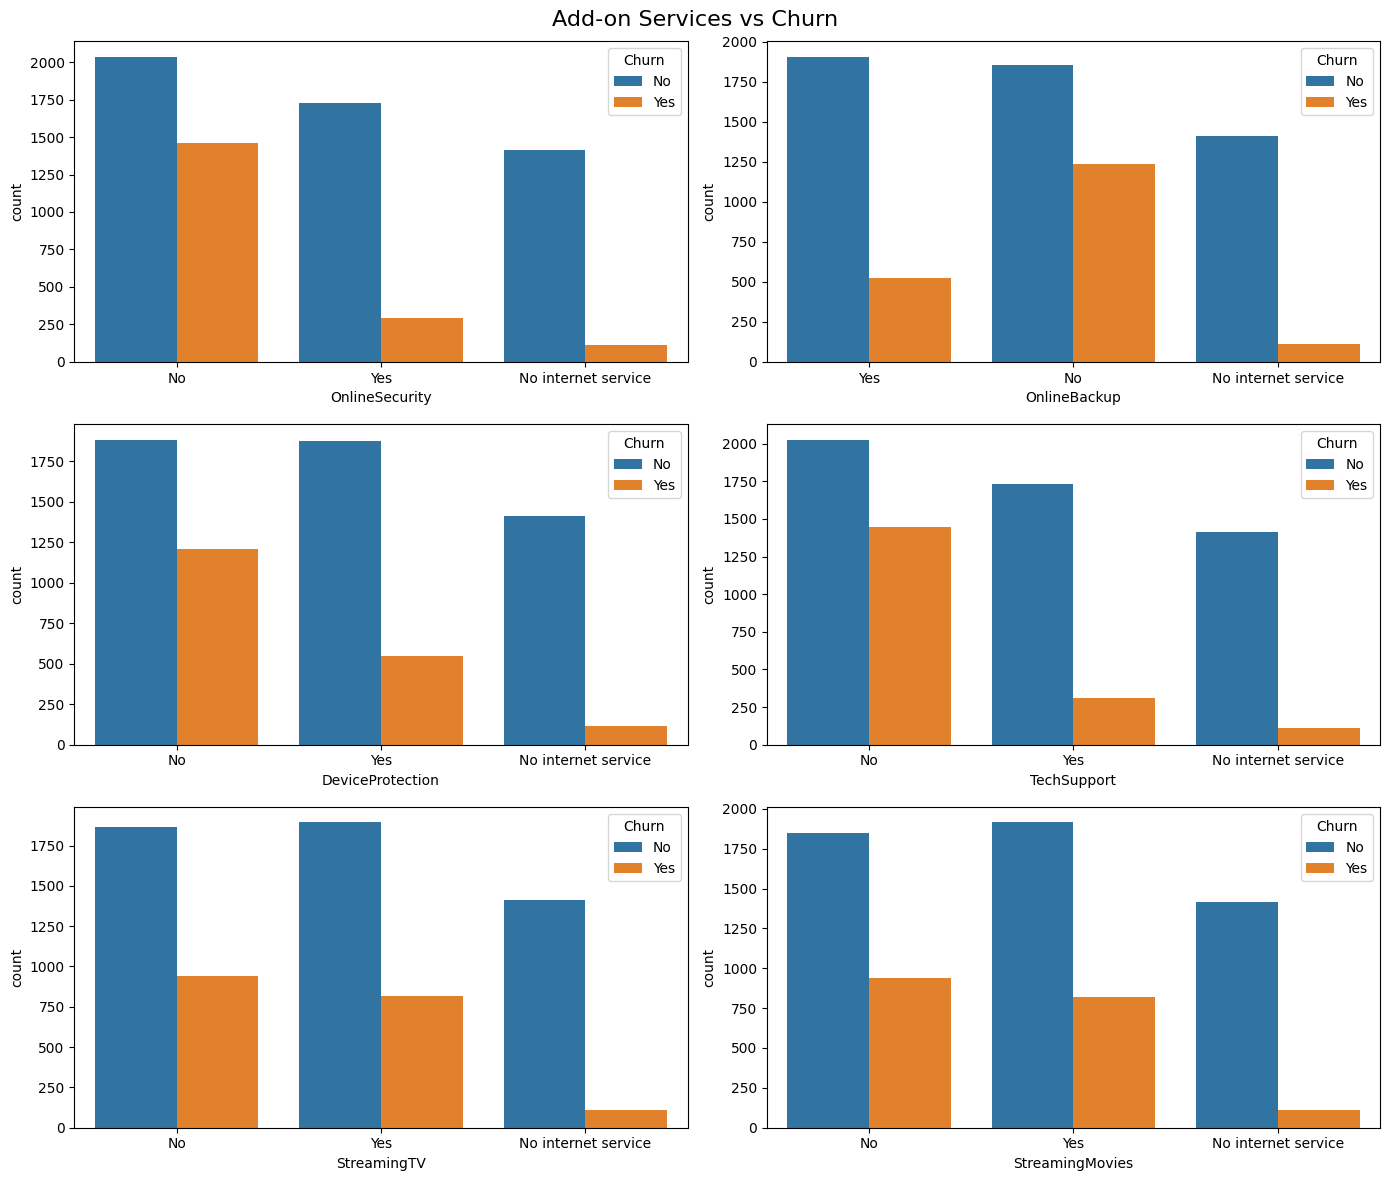

In [15]:
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle('Add-on Services vs Churn', fontsize=16)

for i, col in enumerate(services):
    row = i // 2
    col_idx = i % 2
    # crosstab جوة اللوب عشان نطبع النسب
    print(f"\n--- {col} ---")
    print(pd.crosstab(df[col], df['Churn'], normalize='index')*100)
    
    sns.countplot(x=col, hue='Churn', data=df, ax=axes[row, col_idx])

plt.tight_layout()
plt.show()

In [16]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[0,12,24,48,72], labels=['0-12','12-24','24-48','48-72'])
pd.crosstab(df['TenureGroup'], df['Churn'], normalize='index')*100

Churn,No,Yes
TenureGroup,,
0-12,52.321839,47.678161
12-24,71.289062,28.710938
24-48,79.611041,20.388959
48-72,90.486824,9.513176


In [17]:
print(pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index')*100)
print(pd.crosstab(df['Partner'], df['Churn'], normalize='index')*100)

Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903


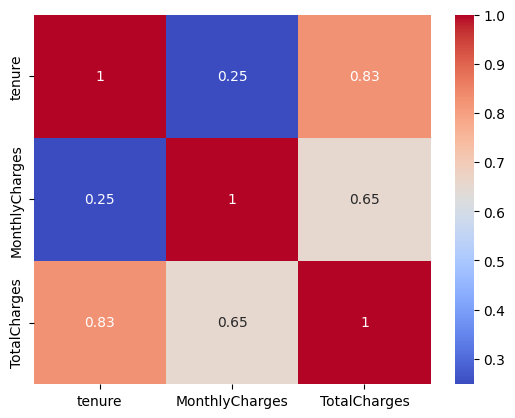

In [18]:
numeric_df = df[['tenure','MonthlyCharges','TotalCharges']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [20]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')